In [55]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

from statstech.linear_model import (
    LinearRegression,
    Ridge,
    Lasso
)

from statstech.metrics import root_mean_squared_error

from statstech.model_selection import (
    KFold,
    GridSearchCV,
    cross_val_score
)

from statstech.pipeline import Pipeline
from statstech.preprocessing import StandardScaler

from analysis.config import SEED
from analysis.io import load_dataset

from analysis.config import FIGURES

In [2]:
cv = KFold(5, shuffle=True, random_state=SEED)

In [3]:
d = load_dataset("enem")
X_train = d["X_train"]
y_train = d["y_train"]
feature_names = d["feature_names"]

In [13]:
baseline_rmse = []
for train_idx, val_idx in cv.split(X_train):

    train_mean = np.mean(y_train[train_idx])

    predictions = np.full(len(val_idx), train_mean)

    rmse = root_mean_squared_error(y_train[val_idx], predictions)

    baseline_rmse.append(rmse)

print(
    f"Baseline RMSE: "
    f"{np.mean(baseline_rmse):.2f} "
    f"+/- {np.std(baseline_rmse):.2f}")

Baseline RMSE: 87.74 +/- 0.54


In [12]:
continues_features_names = ["household_size", "log_income_per_capita", "asset_index_1"]

cols_contiues = [i for i, name in enumerate(feature_names) if name in continues_features_names]

print("Colunas contínuas: ", cols_contiues)

Colunas contínuas:  [8, 9, 40]


In [14]:
linear_model = Pipeline([("scalar", StandardScaler(columns=cols_contiues)),
                         ("model", LinearRegression())])

In [22]:
linear_scores = cross_val_score(linear_model, X_train, y_train, cv=cv, scoring="rmse")

print(f"Regressão Linear RMSE: "
      f"{np.mean(linear_scores):.2f}"
      f" +/-{np.std(linear_scores):.2f}")

Regressão Linear RMSE: 72.87 +/-0.74


In [23]:
linear_model.fit(X_train, y_train)

linear_coefficients = linear_model.named_steps_["model"].coef_

for name, coefficient in zip(feature_names, linear_coefficients):
    print(f"{name:35s} {coefficient:10.3f}")

father_education                         3.581
father_education_unknown               -10.037
mother_education                         4.331
mother_education_unknown               -19.836
father_occupation                        5.469
father_occupation_unknown              -11.873
mother_occupation                        2.814
mother_occupation_unknown               -6.459
household_size                          -2.680
log_income_per_capita                    9.868
school_3                                43.640
region_Nordeste                         10.991
region_Norte                            -3.858
region_Sudeste                           8.702
region_Sul                              -0.115
sex_M                                   -2.228
race_1                                  17.523
race_2                                  -3.096
race_3                                   2.048
race_4                                   1.865
race_5                                 -23.750
age_group_10 

In [26]:
coefficient_table = pd.DataFrame({
    "feature": feature_names,
    "coefficient": linear_coefficients
})

coefficient_table["abs_coefficient"] = (coefficient_table["coefficient"].abs())

coefficient_table = coefficient_table.sort_values(
    "abs_coefficient",
    ascending = False
)

coefficient_table

,feature,coefficient,abs_coefficient
30,age_group_19,-111.959487,111.959487
29,age_group_18,-79.338762,79.338762
28,age_group_17,-78.048591,78.048591
25,age_group_14,-73.696866,73.696866
24,age_group_13,-62.848092,62.848092
23,age_group_12,-57.471328,57.471328
27,age_group_16,-54.509141,54.509141
22,age_group_11,-53.929266,53.929266
26,age_group_15,-53.812035,53.812035
36,age_group_6,-52.082108,52.082108


In [27]:
ridge_alphas = np.logspace(-2, 4, 13)

ridge_alphas

array([1.00000000e-02, 3.16227766e-02, 1.00000000e-01, 3.16227766e-01,
       1.00000000e+00, 3.16227766e+00, 1.00000000e+01, 3.16227766e+01,
       1.00000000e+02, 3.16227766e+02, 1.00000000e+03, 3.16227766e+03,
       1.00000000e+04])

In [31]:
ridge_pipeline = Pipeline([("scaler", StandardScaler(columns=cols_contiues)), ("model", Ridge())])

ridge_search = GridSearchCV(ridge_pipeline, {"model__alpha": ridge_alphas}, cv=cv, scoring="rmse")

In [34]:
ridge_search.fit(X_train, y_train)

print("Best alpha:", ridge_search.best_params_)
print("Best RMSE:", ridge_search.best_score_)

Best alpha: {'model__alpha': np.float64(0.31622776601683794)}
Best RMSE: 72.86668456443977


In [39]:
alpha_scaler = StandardScaler(columns=cols_contiues)

alpha_scaler.fit(X_train)

X_scaled = alpha_scaler.transform(X_train)

In [40]:
X_centered = X_scaled - np.mean(X_scaled, axis=0)
y_centered = y_train - np.mean(y_train)

n_samples = X_centered.shape[0]

alpha_max = np.max(np.abs(X_centered.T @ y_centered)) / n_samples

print("Alpha max: ", alpha_max)

Alpha max:  43.99261764567192


In [ ]:
lasso_alphas = alpha_max * np.logspace(-4, 0, 13)

lasso_max_pipeline = Pipeline([("scaler", StandardScaler(columns=cols_contiues)),
                                ("model", Lasso(alpha=alpha_max))])

lasso_max_pipeline.fit(X_train, y_train)

lasso_max_coefficients = (lasso_max_pipeline.named_steps_["model"].coef_)

print("Maior coeficiente em absoluto:", np.max(np.abs(lasso_max_coefficients)))

print("Todos os coeficientes são zero: ", np.allclose(lasso_max_coefficients, 0))


Maximum absolute coefficient: 0.0
All coefficients are zero:  True


In [ ]:
lasso_alphas = alpha_max * np.logspace(-4, 0, 13)

lasso_pipeline = Pipeline([("scaler", StandardScaler(columns=cols_contiues)),
                           ("model", Lasso())])

lasso_search = GridSearchCV(lasso_pipeline, {"model__alpha": lasso_alphas}, cv=cv, scoring="rmse")

lasso_search.fit(X_train, y_train)

print("Melhor alpha:", lasso_search.best_params_)
print("Melhor RMSE:", lasso_search.best_score_)

Best alpha: {'model__alpha': np.float64(0.004399261764567192)}
Best RMSE: 72.87465199480002


In [51]:
best_lasso = lasso_search.best_estimator_.named_steps_["model"]

print("Iterações:", best_lasso.n_iter_)
print("Iterações máximas:", best_lasso.max_iter)

Iterações: 264
Iterações máximas: 1000


In [53]:
lasso_path_coefficients = [] 
lasso_path_iterations = []

for alpha in lasso_alphas:

    model = Pipeline([("scaler", StandardScaler(columns=cols_contiues)),
                      ("model", Lasso(alpha=alpha))])

    model.fit(X_train, y_train)

    fitted_lasso = model.named_steps_["model"]

    lasso_path_coefficients.append(fitted_lasso.coef_)

    lasso_path_iterations.append(fitted_lasso.n_iter_)

lasso_path_coefficients = np.array(lasso_path_coefficients)

print("Formato da matriz de coeficientes", lasso_path_coefficients.shape)
print("Máximo de iterações", max(lasso_path_iterations))




Formato da matriz de coeficientes (13, 41)
Máximo de iterações 264


<function matplotlib.pyplot.show(close=None, block=None)>

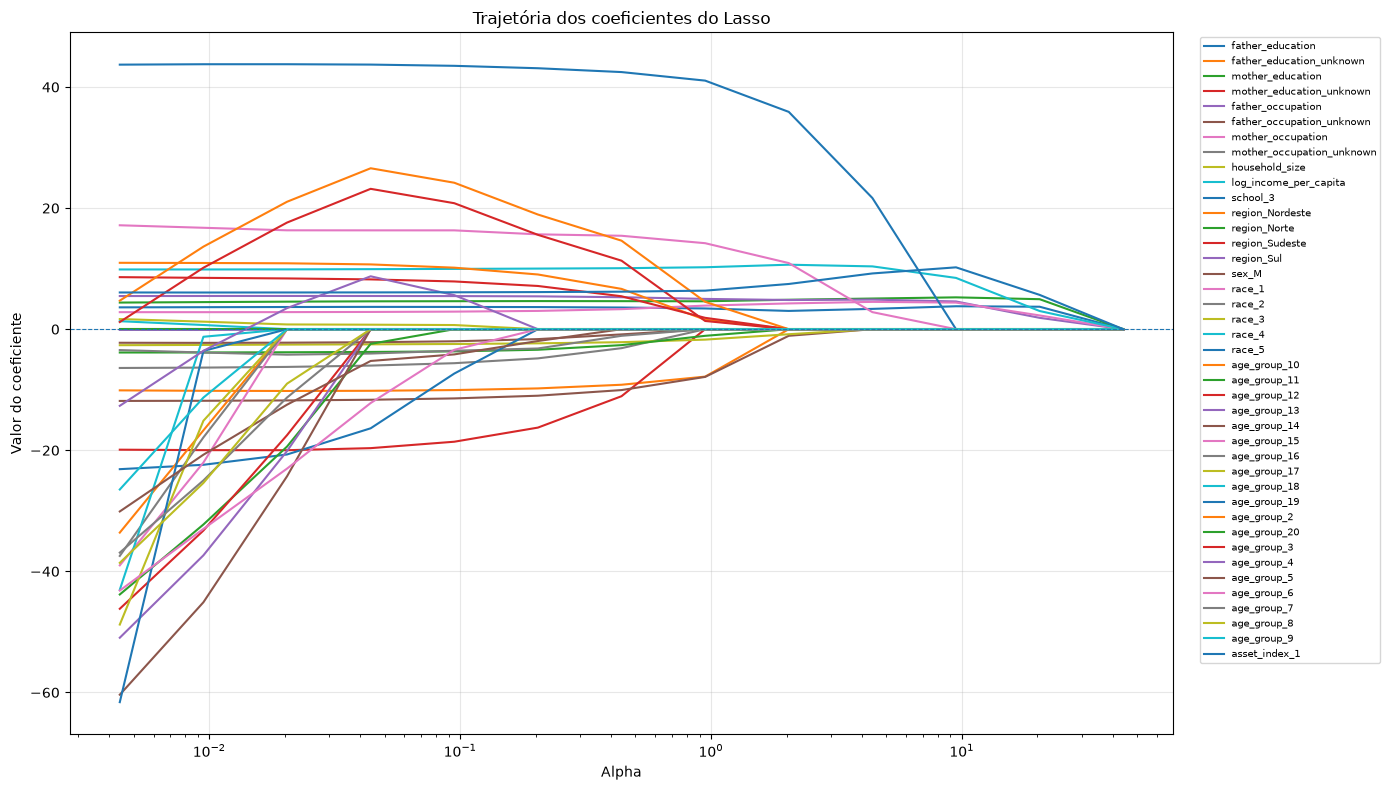

In [56]:
fig, ax = plt.subplots(figsize=(14, 8))

for i, feature in enumerate(feature_names):
    ax.plot(lasso_alphas,
            lasso_path_coefficients[:, i],
            label=feature)

ax.set_xscale("log")
ax.axhline(0, linewidth=0.8, linestyle="--")

ax.set_xlabel("Alpha")
ax.set_ylabel("Valor do coeficiente")
ax.set_title("Trajetória dos coeficientes do Lasso")

ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=7)

ax.grid(alpha=0.3)
fig.tight_layout()

plt.show

In [57]:
FIGURES.mkdir(parents=True, exist_ok=True)

fig.savefig(
    FIGURES / "enem_lasso_caminho.png",
    dpi=200,
    bbox_inches="tight" 
)

In [58]:
dataset_onehot = load_dataset("enem_onehot")

X_train_onehot = dataset_onehot["X_train"]
y_train_onehot = dataset_onehot["y_train"]

feature_names_onehot = dataset_onehot["feature_names"]

print("Formato dos preditores:", X_train_onehot.shape)
print("Formato dos alvos", y_train_onehot.shape)
print("Mesmos alvos do conjunto ordinal:", np.array_equal(y_train, y_train_onehot))

Formato dos preditores: (38347, 66)
Formato dos alvos (38347,)
Mesmos alvos do conjunto ordinal: True


In [59]:
cols_contiues_onehot = [i for i, name in enumerate(feature_names_onehot) if name in continues_features_names]
print("Colunas contínuas:", cols_contiues_onehot)

Colunas contínuas: [4, 65]


In [60]:
ridge_onehot_pipeline = Pipeline([
    ("scaler", StandardScaler(columns=cols_contiues_onehot)),
    ("model", Ridge())
])

ridge_onehot_search = GridSearchCV(
    ridge_onehot_pipeline,
    {"model__alpha": ridge_alphas},
    cv=cv,
    scoring="rmse"
)


In [61]:
ridge_onehot_search.fit(X_train_onehot, y_train_onehot)


print("Melhor alpha:", ridge_onehot_search.best_params_)

print("Melhor RMSE:", ridge_onehot_search.best_score_)

Melhor alpha: {'model__alpha': np.float64(0.31622776601683794)}
Melhor RMSE: 72.475243691309


In [62]:
ordinal_results = ridge_search.cv_results_[ridge_search.best_index_]

onehot_results = ridge_onehot_search.cv_results_[ridge_onehot_search.best_index_]

encoding_comparison = pd.DataFrame([
    {
        "Codificação": "Original",
        "Melhor alpha": ridge_search.best_params_["model__alpha"],
        "RMSE médio": ridge_search.best_score_,
        "Desvio médio entre os folds": ordinal_results["std_score"]
    },
    {
        "Codificação": "One-hot",
        "Melhor alpha": ridge_onehot_search.best_params_["model__alpha"],
        "RMSE médio": ridge_onehot_search.best_score_,
        "Desvio médio entre os folds": onehot_results["std_score"]
    }
])

encoding_comparison

,Codificação,Melhor alpha,RMSE médio,Desvio médio entre os folds
0,Original,0.316228,72.866685,0.825659
1,One-hot,0.316228,72.475244,0.783703


In [ ]:
folding_comparison = pd.DataFrame({
    "Fold": range(1, 6),
    "Ordinal": ordinal_results["scores"],
    "One-hot": onehot_results["scores"]
})

folding_comparison["Diferença"] = (
    folding_comparison["Ordinal"] - folding_comparison["One-hot"]
)

folding_comparison

,Fold,Ordinal,One-hot,Diferença
0,1,74.265104,73.794019,0.471085
1,2,72.277906,72.021345,0.256561
2,3,72.909589,72.554688,0.354901
3,4,72.268140,71.830762,0.437377
4,5,72.612684,72.175404,0.437280
